<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 13: Sequential Dataset Preparation and RNN Prediction

1. Load the series with Pandas, handle missing values and scale it

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

np.random.seed(42)
hours = np.arange(24 * 90)
demand = 100 + 20*np.sin(2*np.pi*hours/24) + 0.005*hours
demand += np.random.normal(0, 3, len(hours))

df = pd.DataFrame({'Demand': demand})
df.loc[10:15, 'Demand'] = np.nan
df['Demand'] = df['Demand'].interpolate()

values = df['Demand'].values
vmin, vmax = values.min(), values.max()
scaled = (values - vmin) / (vmax - vmin)

print(df.head())
print("Missing values:", df.isnull().sum().sum())


       Demand
0  101.490142
1  104.766588
2  111.953066
3  118.726225
4  116.638048
Missing values: 0


2. Create sliding windows (24 past hours → next hour)

In [2]:

X, y = [], []

for i in range(24, len(scaled)):
    X.append(scaled[i-24:i])
    y.append(scaled[i])

X = np.array(X).reshape(-1, 24, 1)
y = np.array(y)

print("Input shape:", X.shape)
print("Output shape:", y.shape)


Input shape: (2136, 24, 1)
Output shape: (2136,)


3. Split chronologically into train and test sets

In [3]:

split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 1708
Testing samples: 428


4. Build and train a SimpleRNN model

In [4]:

model = tf.keras.Sequential([
    tf.keras.Input(shape=(24, 1)),
    tf.keras.layers.SimpleRNN(32, activation='tanh'),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=10, batch_size=32, verbose=1)

print("RNN training completed!")


Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0430
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0064
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0055
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0050
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0045
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0042
Epoch 7/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0040
Epoch 8/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0035
Epoch 9/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0036
Epoch 10/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0035
RNN training completed!


5. Plot actual vs predicted demand and calculate MAE and RMSE

MAE: 3.07
RMSE: 3.85


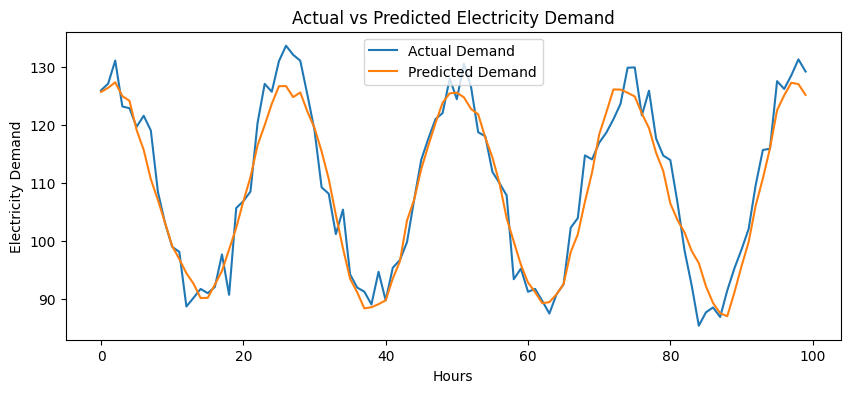

In [5]:

pred = model.predict(X_test, verbose=0).flatten()

# Convert normalized values back to original scale
actual = y_test * (vmax - vmin) + vmin
predicted = pred * (vmax - vmin) + vmin

mae = np.mean(np.abs(actual - predicted))
rmse = np.sqrt(np.mean((actual - predicted)**2))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

plt.figure(figsize=(10, 4))
plt.plot(actual[:100], label='Actual Demand')
plt.plot(predicted[:100], label='Predicted Demand')
plt.xlabel('Hours')
plt.ylabel('Electricity Demand')
plt.title('Actual vs Predicted Electricity Demand')
plt.legend()
plt.show()
